In [1]:
PROFILE = "full"             # "sample" or "full"
CONFIG_NAME = "alt_partitions8"    # "reference" or "alt_partitions8"
REPEAT = 3                  # 1, 2 or 3

import findspark; findspark.init("/usr/lib/spark")
import subprocess, re, time, json
from pathlib import Path
from contextlib import contextmanager

SHUFFLE_PARTITIONS = 200 if CONFIG_NAME == "reference" else 8
RUN_ID = f"{PROFILE}_{CONFIG_NAME}_r{REPEAT}"
INPUT = {"full": "/project/inputs/full/all_stocks_5yr.csv",
         "sample": "/project/inputs/sample/all_stocks_5yr_sample.csv"}[PROFILE]
RAW_PATH = "/project/raw/prices/" + INPUT.split("/")[-1]
RUN_DIR = f"/project/runs/{RUN_ID}"
OUT_BASE = f"hdfs://{RUN_DIR}/task3"     # Task 3 outputs; fresh folder per run
OUTPUT_BASE = OUT_BASE                  # name Task 4 expects
STREAMING_JAR = "/usr/lib/hadoop-mapreduce/hadoop-streaming.jar"
EVID = Path("task5_outputs") / RUN_ID; EVID.mkdir(parents=True, exist_ok=True)

APP_IDS, PIPE_T = [], {}
def sh(cmd, check=True):
    print("$", cmd)
    p = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    out = p.stdout + p.stderr
    with open(EVID / "commands.log", "a") as f:
        f.write(f"\n$ {cmd}\n{out}\n[exit {p.returncode}]\n")
    APP_IDS.extend(sorted(set(re.findall(r"application_\d+_\d+", out))))
    if check and p.returncode != 0:
        print(out[-3000:]); raise RuntimeError(f"Command failed: {cmd}")
    return p.stdout

@contextmanager
def timed(name):
    t0 = time.time(); yield
    PIPE_T[name] = round(time.time() - t0, 1); print(f"[pipeline] {name}: {PIPE_T[name]} s")

print(RUN_ID, INPUT, OUT_BASE)

full_alt_partitions8_r3 /project/inputs/full/all_stocks_5yr.csv hdfs:///project/runs/full_alt_partitions8_r3/task3


In [2]:
for p in ["/project/raw/prices", "/project/audit", "/project/prepared", RUN_DIR]:
    sh(f"hadoop fs -rm -r -f -skipTrash {p}")
sh(f"hadoop fs -mkdir -p /project/raw/prices /project/audit /project/prepared {RUN_DIR}")
sh(f"hadoop fs -cp {INPUT} {RAW_PATH}")

$ hadoop fs -rm -r -f -skipTrash /project/raw/prices
$ hadoop fs -rm -r -f -skipTrash /project/audit
$ hadoop fs -rm -r -f -skipTrash /project/prepared
$ hadoop fs -rm -r -f -skipTrash /project/runs/full_alt_partitions8_r3
$ hadoop fs -mkdir -p /project/raw/prices /project/audit /project/prepared /project/runs/full_alt_partitions8_r3
$ hadoop fs -cp /project/inputs/full/all_stocks_5yr.csv /project/raw/prices/all_stocks_5yr.csv


''

In [3]:
T0 = time.time()
with timed("t2_streaming_audit"):
    sh(f"hadoop jar {STREAMING_JAR} -D mapreduce.job.reduces=1 -D stream.num.map.output.key.fields=2 "
       "-files task2/streaming/mapper.py#mapper.py,task2/streaming/reducer.py#reducer.py,task2/lib/rules.py#rules.py "
       f"-mapper 'python3 mapper.py' -reducer 'python3 reducer.py' -input {RAW_PATH} -output /project/audit/price_row_audit")
with timed("t2_hive_register"):
    sh("hive -f task2/hive/01_register.sql")
with timed("t2_spark_features"):
    sh(f"spark-submit --conf spark.sql.shuffle.partitions={SHUFFLE_PARTITIONS} "
       f"--py-files task2/lib/rules.py,task2/lib/weekly.py task2/spark/prepare_features.py {RAW_PATH} /project/prepared")
with timed("t2_hive_reconcile"):
    print(sh("hive -f task2/hive/02_reconcile.sql"))

$ hadoop jar /usr/lib/hadoop-mapreduce/hadoop-streaming.jar -D mapreduce.job.reduces=1 -D stream.num.map.output.key.fields=2 -files task2/streaming/mapper.py#mapper.py,task2/streaming/reducer.py#reducer.py,task2/lib/rules.py#rules.py -mapper 'python3 mapper.py' -reducer 'python3 reducer.py' -input /project/raw/prices/all_stocks_5yr.csv -output /project/audit/price_row_audit
[pipeline] t2_streaming_audit: 32.1 s
$ hive -f task2/hive/01_register.sql
[pipeline] t2_hive_register: 12.4 s
$ spark-submit --conf spark.sql.shuffle.partitions=8 --py-files task2/lib/rules.py,task2/lib/weekly.py task2/spark/prepare_features.py /project/raw/prices/all_stocks_5yr.csv /project/prepared
[pipeline] t2_spark_features: 141.2 s
$ hive -f task2/hive/02_reconcile.sql
raw_rows	619040
cleaned_rows	605887
rejected_rows	13153
out_of_range	13130
close_outside_range	8
bad_price	7
bad_price|bad_volume	4
open_outside_range	3
high_below_low|open_outside_range|close_outside_range	1
test	25441	2017-01-06	2017-12-22
tr

In [4]:
from pyspark.sql import SparkSession
with timed("spark_session_start"):
    spark = (SparkSession.builder.appName(f"task5_{RUN_ID}").master("yarn")
             .config("spark.sql.shuffle.partitions", str(SHUFFLE_PARTITIONS))
             .enableHiveSupport().getOrCreate())
APP_IDS.append(spark.sparkContext.applicationId)
c = {r["split"]: r["n"] for r in spark.sql("SELECT `split`, COUNT(*) AS n FROM project.weekly_all GROUP BY `split`").collect()}
TASK2_EXPECTED_ROWS = {"train": c.get("train", 0), "val": c.get("validation", 0), "test": c.get("test", 0)}
print(TASK2_EXPECTED_ROWS)
T3 = time.time()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/10 10:13:25 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


[pipeline] spark_session_start: 13.5 s


26/11/10 10:13:35 WARN HiveConf: HiveConf of name hive.server2.thrift.url does not exist


{'train': 66907, 'val': 25310, 'test': 25441}


In [5]:
import json, sys, time, datetime
from pathlib import Path
from contextlib import contextmanager
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
 
# ---------- EDIT THESE (the only cell that needs to be changed between local and EMR) ----------
SEED = 42
TRAIN_TABLE   = "project.weekly_train"           # CHANGED (Task 5): Hive tables in the "project" database
VAL_TABLE     = "project.weekly_validation"      # CHANGED (Task 5)
TEST_TABLE    = "project.weekly_test"            # CHANGED (Task 5)
WEEKLY_DIR    = None                             # CHANGED (Task 5): None = read the Hive tables on EMR
# OUT_BASE is NOT set here any more.             # CHANGED (Task 5): Cell 1 sets it to hdfs:///project/runs/<RUN_ID>/task3
EXPECTED_SPARK_PREFIX = "3.5"                    # EMR 7.10 ships Spark 3.5.x
STRICT_VERSION_CHECK  = True                     # CHANGED (Task 5): stop the run if the Spark version is different
 
# -----------------------------------------------------------------------------------------------
 
FEATURES_PATH = OUT_BASE + "/weekly_features" # engineered features
MODEL_PATH    = OUT_BASE + "/model_best" # saved final model
REF_PRED_PATH = OUT_BASE + "/reference_test_predictions" # test predictions for reproducibility. Test against the re-loaded model.
WEIGHTS_PATH  = OUT_BASE + "/test_weights" # weights built from the test predictions
EVIDENCE_PATH = OUT_BASE + "/evidence" # JSON logs, metrics, timings
TOL = 1e-9                     # reload-check tolerance on predicted volatility
FLOOR_PCT = 0.05               # predicted volatility is floored at this percentile of the TRAINING weekly volatilities before taking 1 / vol
 
# Define the time period to have data used for testing, validating and testing.
SPLITS = {"train": ("2013-01-01", "2015-12-31"),
          "val":   ("2016-01-01", "2016-12-31"),
          "test":  ("2017-01-01", "2017-12-31")}
 
# List of feature columns from Task 2
FEATS = ["vol_1w", "vol_4w", "vol_12w", "vol_52w", "high_low_range", "weekly_return", "volume_vs_normal", "split_flag"]
# vol_1w/4w/12w/52w = past volatility over 1/4/12/52 weeks. vol_52w was already filled with the TRAINING median in Task 2.
 
# TASK2_EXPECTED_ROWS is NOT set here any more.  # CHANGED (Task 5): Cell 4 sets it from the real Hive counts
print("Task 2 weekly rows (from Cell 4):", TASK2_EXPECTED_ROWS)
 
# Starts Spark, or reuses the one EMR already gave you.
spark = SparkSession.builder.appName("inf2006_task3").getOrCreate()   # returns the session Cell 4 started
print("Spark", spark.version)
 
# Spark version check: the final run is on EMR. A model saved with a different Spark version may not load there.
SPARK_VERSION_OK = spark.version.startswith(EXPECTED_SPARK_PREFIX)
if not SPARK_VERSION_OK:
    msg = f"Spark {spark.version} is not the expected {EXPECTED_SPARK_PREFIX}.x. A model saved here may not load on EMR, so save the FINAL model on EMR."
    if STRICT_VERSION_CHECK:
        raise RuntimeError(msg)
    print("WARNING:", msg)
 
# Timer helper to track performance later.
TIMINGS = {}
@contextmanager
def stage(name):
    t0 = time.time(); yield
    TIMINGS[name] = round(time.time() - t0, 2); print(f"[timing] {name}: {TIMINGS[name]}s")
 
# Helper function that saves any Python dictionary as a text file in HDFS (or local filesystem).
def save_json(obj, path):
    spark.createDataFrame([(json.dumps(obj, indent=2, default=str),)], ["json"]).coalesce(1).write.mode("overwrite").text(path)
 
# Helpers to look at HDFS / local folders through Hadoop's FileSystem API (work for hdfs:// and file:// paths).
def _hadoop_fs(path):
    jpath = spark._jvm.org.apache.hadoop.fs.Path(path)
    return jpath, jpath.getFileSystem(spark.sparkContext._jsc.hadoopConfiguration())
 
def path_exists(path):
    try:
        jpath, fs = _hadoop_fs(path); return fs.exists(jpath)
    except Exception:
        return False
 
def path_bytes(path):
    try:
        jpath, fs = _hadoop_fs(path); return fs.getContentSummary(jpath).getLength()
    except Exception as e:
        return f"unavailable ({type(e).__name__})"
 

Task 2 weekly rows (from Cell 4): {'train': 66907, 'val': 25310, 'test': 25441}
Spark 3.5.5-amzn-1


26/11/10 10:13:42 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [6]:
# Returns "is column c between date a and date b?". Used later to check that every row falls inside its own period
# (train/val/test).
def in_range(c, a, b):
    return (F.col(c) >= F.to_date(F.lit(a))) & (F.col(c) <= F.to_date(F.lit(b)))
 
# Read one Task 2 weekly table: from Hive on EMR, or from Task 2's CSV files locally (WEEKLY_DIR).
# Renames ticker -> symbol and target_next_vol -> label (the name Spark ML expects for the thing being predicted).
def load_weekly(table, csv_name, period):
    df = spark.table(table) if WEEKLY_DIR is None else spark.read.csv(f"{WEEKLY_DIR}/{csv_name}", header=True, inferSchema=True)
    # split_flag may arrive as boolean, 0/1 or the text True/False, so turn it into 1.0 / 0.0 explicitly.
    flag = F.when(F.lower(F.col("split_flag").cast("string")).isin("true", "1", "1.0"), F.lit(1.0)).otherwise(F.lit(0.0))
    return df.select(F.col("ticker").alias("symbol"),
                     F.to_date(F.col("anchor_date")).alias("anchor_date"),
                     F.to_date(F.col("next_anchor_date")).alias("next_anchor_date"),
                     F.lit(period).alias("period"),
                     F.col("target_next_vol").cast("double").alias("label"),
                     flag.alias("split_flag"),
                     *[F.col(c).cast("double").alias(c) for c in FEATS if c != "split_flag"])
 
with stage("build_weekly_table"):
    # Stack the three Task 2 tables. The period comes from which table the row was read from (no random shuffling).
    wk = (load_weekly(TRAIN_TABLE, "weekly_train.csv", "train")
            .unionByName(load_weekly(VAL_TABLE, "weekly_validation.csv", "val"))
            .unionByName(load_weekly(TEST_TABLE, "weekly_test.csv", "test")))
 
 
    # ---- period + boundary rule + status
    # Task 2 already applied these rules. They are re-checked here, so any violation shows up in the exclusions table.
    # Find the first and last day of each period.
    period_start = (F.when(F.col("period") == "train", F.to_date(F.lit(SPLITS["train"][0])))
                     .when(F.col("period") == "val",   F.to_date(F.lit(SPLITS["val"][0])))
                     .when(F.col("period") == "test",  F.to_date(F.lit(SPLITS["test"][0]))))
    period_end = (F.when(F.col("period") == "train", F.to_date(F.lit(SPLITS["train"][1])))
                   .when(F.col("period") == "val",   F.to_date(F.lit(SPLITS["val"][1])))
                   .when(F.col("period") == "test",  F.to_date(F.lit(SPLITS["test"][1]))))
 
    wk = wk.withColumn("status",
            F.when(F.col("label").isNull(), "target_unavailable")  # <- target missing
             .when(F.col("vol_12w").isNull(), "baseline_unavailable")  # <- the 12-week baseline needs vol_12w, so model and baseline use the same rows
             .when((F.col("anchor_date") < period_start) | (F.col("anchor_date") > period_end), "outside_periods")  # <- anchor date not inside its own period
             .when(F.col("next_anchor_date").isNull() | (F.col("next_anchor_date") > period_end), "crosses_boundary")  # <- prediction window goes past the allowed period.
                                                                                                                       # The "next week" anchor date is missing or lies outside the allowed period.
                                                                                                                       # That means the label would require future data we're not allowed to use.
             .otherwise("ok"))  # <- Safe to use
 
    keep = ["symbol", "anchor_date", "next_anchor_date", "period", "status", "label"] + FEATS
    if path_exists(FEATURES_PATH):
      print("WARNING: output path already exists and will be overwritten.")
    wk.select(*keep).write.mode("overwrite").parquet(FEATURES_PATH)
 
data = spark.read.parquet(FEATURES_PATH)
summary = data.groupBy("period", "status").count().orderBy("period", "status")
summary.show(50, truncate=False)           # <- row counts and exclusions per split (paste into the report)
cov = (data.filter("status = 'ok'").groupBy("period")
           .agg(F.min("anchor_date").alias("first_anchor"), F.max("anchor_date").alias("last_anchor"),
                F.count("*").alias("rows"), F.avg("label").alias("mean_vol"), F.stddev("label").alias("std_vol")).orderBy("period"))
cov.show(truncate=False)
 
# Reconcile with the Task 2 hand-off: the rows loaded here should equal the weekly counts Task 2 reported.
loaded_counts = {r["period"]: r["count"] for r in data.groupBy("period").count().collect()}
print("rows loaded:", loaded_counts, "| expected from Task 2:", TASK2_EXPECTED_ROWS, "| match:", loaded_counts == TASK2_EXPECTED_ROWS)
 
# Null check: Task 2 already filled vol_52w, so every feature should have 0 nulls in every period.
data.groupBy("period").agg(*[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in FEATS]).orderBy("period").show(truncate=False)

[timing] build_weekly_table: 3.12s
+------+------+-----+
|period|status|count|
+------+------+-----+
|test  |ok    |25441|
|train |ok    |66907|
|val   |ok    |25310|
+------+------+-----+

+------+------------+-----------+-----+--------------------+--------------------+
|period|first_anchor|last_anchor|rows |mean_vol            |std_vol             |
+------+------------+-----------+-----+--------------------+--------------------+
|test  |2017-01-06  |2017-12-22 |25441|0.011173448873767824|0.0093649682764863  |
|train |2013-05-10  |2015-12-24 |66907|0.012599516195078752|0.009367644656359999|
|val   |2016-01-08  |2016-12-23 |25310|0.014090359028523102|0.011495710018624235|
+------+------------+-----------+-----+--------------------+--------------------+

rows loaded: {'train': 66907, 'test': 25441, 'val': 25310} | expected from Task 2: {'train': 66907, 'val': 25310, 'test': 25441} | match: True
+------+------+------+-------+-------+--------------+-------------+----------------+--------

In [7]:
ok = data.filter("status = 'ok'")
train, val, test = [ok.filter(F.col("period") == p).cache() for p in ["train", "val", "test"]]
print("rows  train/val/test:", train.count(), val.count(), test.count())
 
# Regression metrics: lower RMSE / MAE is better; R2 above 0 means better than predicting the mean of the evaluated set.
def metrics(df, pred="prediction"):
    ev = lambda m: RegressionEvaluator(labelCol="label", predictionCol=pred, metricName=m).evaluate(df)
    return {"rmse": round(ev("rmse"), 6), "mae": round(ev("mae"), 6), "r2": round(ev("r2"), 4)}
 
# Baseline model
# Predict that next week's volatility equals the volatility over the previous 12 weeks.
# uses vol_12w from Task 2: standard deviation of the daily log returns over the previous 12 completed weeks (known on the anchor morning).
def baseline_vol_12w(df):
    return df.withColumn("prediction", F.col("vol_12w"))
 
# The ML model must beat these baselines, otherwise it's not useful.
BASELINES = {"vol_12w": baseline_vol_12w}
 
# For each baseline model, run it on the validation dataset, compute metrics, and store the results.
base_val = {k: metrics(f(val)) for k, f in BASELINES.items()}
print("baselines on VALIDATION:", base_val)

rows  train/val/test: 66907 25310 25441
baselines on VALIDATION: {'vol_12w': {'rmse': 0.011139, 'mae': 0.007658, 'r2': 0.0611}}


In [8]:
# Every candidate model uses this pipeline.
# Imputer fills missing values (Task 2 already filled vol_52w from the training rows, so this is only a safeguard; it is fitted on training data only).
# Assembler combines features.
# Scaler normalizes them.
# clf is the model (Linear Regression, RF, GBT).
# feats is the list of feature columns.
def make_pipeline(clf, feats=FEATS):
    imp_cols = [c + "_imp" for c in feats]
    return Pipeline(stages=[
        Imputer(inputCols=feats, outputCols=imp_cols, strategy="median"), # If missing value, imputer fills it with median.
        VectorAssembler(inputCols=imp_cols, outputCol="raw_features", handleInvalid="keep"), # Take the 8 features and make it into a single column.
        StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True), # Make features have comparable scale.
        clf])
 
# List of candidates: Linear Regression, Random Forest, Gradient Boosted Trees.
CANDIDATES = []
for reg in [0.0, 0.01, 0.1]:
    CANDIDATES.append(("linreg", {"regParam": reg}, lambda reg=reg: LinearRegression(labelCol="label", featuresCol="features", regParam=reg, elasticNetParam=0.0, maxIter=100)))
for nt in [50, 100]:
    for md_ in [4, 6]:
        CANDIDATES.append(("random_forest", {"numTrees": nt, "maxDepth": md_},
            lambda nt=nt, md_=md_: RandomForestRegressor(labelCol="label", featuresCol="features", numTrees=nt, maxDepth=md_, seed=SEED)))
for it in [20, 50]:
    for md_ in [3, 5]:
        CANDIDATES.append(("gbt", {"maxIter": it, "maxDepth": md_},
            lambda it=it, md_=md_: GBTRegressor(labelCol="label", featuresCol="features", maxIter=it, maxDepth=md_, seed=SEED)))
 
# This runs the model and adds a "prediction" column with the predicted volatility for next week.
def score_df(model, df):
    return model.transform(df)
 
results, fitted = [], []
# For each candidate model: build the pipeline, fit on training data, evaluate on validation, save the metrics, print them.
with stage("train_and_validate_all"):
    for name, params, mk in CANDIDATES:
        t0 = time.time()
        m = make_pipeline(mk()).fit(train)
        r = metrics(score_df(m, val))
        results.append({"model": name, "params": json.dumps(params), **{"val_" + k: v for k, v in r.items()}, "fit_s": round(time.time() - t0, 1)})
        fitted.append(m)
        print(results[-1])
 
# Print table sorted by validation RMSE (lowest first). The model with the lowest validation RMSE is chosen.
spark.createDataFrame(results).orderBy(F.asc("val_rmse")).show(50, truncate=False)

26/11/10 10:13:58 WARN Instrumentation: [e25107bb] regParam is zero, which might cause numerical instability and overfitting.
26/11/10 10:13:58 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/10 10:13:58 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS
26/11/10 10:13:58 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


{'model': 'linreg', 'params': '{"regParam": 0.0}', 'val_rmse': 0.010168, 'val_mae': 0.006615, 'val_r2': 0.2177, 'fit_s': 5.3}
{'model': 'linreg', 'params': '{"regParam": 0.01}', 'val_rmse': 0.010327, 'val_mae': 0.006609, 'val_r2': 0.193, 'fit_s': 1.9}
{'model': 'linreg', 'params': '{"regParam": 0.1}', 'val_rmse': 0.011095, 'val_mae': 0.006956, 'val_r2': 0.0685, 'fit_s': 1.5}


{'model': 'random_forest', 'params': '{"numTrees": 50, "maxDepth": 4}', 'val_rmse': 0.010344, 'val_mae': 0.006623, 'val_r2': 0.1904, 'fit_s': 4.5}


{'model': 'random_forest', 'params': '{"numTrees": 50, "maxDepth": 6}', 'val_rmse': 0.010252, 'val_mae': 0.006613, 'val_r2': 0.2047, 'fit_s': 4.7}


{'model': 'random_forest', 'params': '{"numTrees": 100, "maxDepth": 4}', 'val_rmse': 0.010348, 'val_mae': 0.006625, 'val_r2': 0.1897, 'fit_s': 4.7}


26/11/10 10:14:21 WARN DAGScheduler: Broadcasting large task binary with size 1063.0 KiB


{'model': 'random_forest', 'params': '{"numTrees": 100, "maxDepth": 6}', 'val_rmse': 0.010242, 'val_mae': 0.006609, 'val_r2': 0.2062, 'fit_s': 7.5}
{'model': 'gbt', 'params': '{"maxIter": 20, "maxDepth": 3}', 'val_rmse': 0.010321, 'val_mae': 0.006687, 'val_r2': 0.1939, 'fit_s': 7.6}
{'model': 'gbt', 'params': '{"maxIter": 20, "maxDepth": 5}', 'val_rmse': 0.010282, 'val_mae': 0.006687, 'val_r2': 0.2, 'fit_s': 9.5}
{'model': 'gbt', 'params': '{"maxIter": 50, "maxDepth": 3}', 'val_rmse': 0.010263, 'val_mae': 0.006653, 'val_r2': 0.203, 'fit_s': 13.6}
{'model': 'gbt', 'params': '{"maxIter": 50, "maxDepth": 5}', 'val_rmse': 0.010327, 'val_mae': 0.006718, 'val_r2': 0.193, 'fit_s': 21.5}
[timing] train_and_validate_all: 82.27s
+-----+-------------+--------------------------------+--------+------+--------+
|fit_s|model        |params                          |val_mae |val_r2|val_rmse|
+-----+-------------+--------------------------------+--------+------+--------+
|5.3  |linreg       |{"regParam

In [9]:
# Plain baseline: next week's volatility = vol_12w (no learning, no training)
# Calibrated baseline: a Linear Regression using ONLY vol_12w as the feature.
# If the calibrated baseline is already close to the full model, most of the gain comes from rescaling vol_12w
# rather than from the additional features.
cal_model = make_pipeline(LinearRegression(labelCol="label", featuresCol="features", regParam=0.0, maxIter=100),
                          feats=["vol_12w"]).fit(train)
cal_val = metrics(score_df(cal_model, val))
best_val = min(results, key=lambda r: r["val_rmse"])
print("plain baseline (vol_12w as is)      VAL:", base_val["vol_12w"])
print("calibrated (linear on vol_12w only) VAL:", cal_val)
print("best model (all features)           VAL:", {k: v for k, v in best_val.items() if k.startswith("val_")})
 

26/11/10 10:15:18 WARN Instrumentation: [c938919c] regParam is zero, which might cause numerical instability and overfitting.


plain baseline (vol_12w as is)      VAL: {'rmse': 0.011139, 'mae': 0.007658, 'r2': 0.0611}
calibrated (linear on vol_12w only) VAL: {'rmse': 0.010483, 'mae': 0.006693, 'r2': 0.1684}
best model (all features)           VAL: {'val_rmse': 0.010168, 'val_mae': 0.006615, 'val_r2': 0.2177}


In [10]:
# Do not change anything after this cell based on test results.
best_i = min(range(len(results)), key=lambda i: results[i]["val_rmse"])
best, best_model = results[best_i], fitted[best_i]
print("FINAL:", best["model"], best["params"], "| validation:", {k: v for k, v in best.items() if k.startswith("val_")})
 
# Run the winning model on the test dataset and compute the metrics.
with stage("test_evaluation"):
    test_pred = score_df(best_model, test).cache()
    test_metrics = metrics(test_pred)
    base_test = {k: metrics(f(test)) for k, f in BASELINES.items()}     # <- Run the 12-week average baseline on the same test rows.
print("TEST  model   :", test_metrics); print("TEST  baselines:", base_test)
test_pred.select(F.avg("label").alias("avg_actual_vol"), F.avg("prediction").alias("avg_predicted_vol")).show()   # <- bias check

FINAL: linreg {"regParam": 0.0} | validation: {'val_rmse': 0.010168, 'val_mae': 0.006615, 'val_r2': 0.2177}
[timing] test_evaluation: 0.69s
TEST  model   : {'rmse': 0.008882, 'mae': 0.005631, 'r2': 0.1005}
TEST  baselines: {'vol_12w': {'rmse': 0.009849, 'mae': 0.006395, 'r2': -0.106}}
+--------------------+--------------------+
|      avg_actual_vol|   avg_predicted_vol|
+--------------------+--------------------+
|0.011173448873767824|0.012309582272202864|
+--------------------+--------------------+



In [11]:
cal_test = metrics(score_df(cal_model, test))
print("plain baseline (vol_12w as is)      TEST:", base_test["vol_12w"])
print("calibrated (linear on vol_12w only) TEST:", cal_test)
print("final model (all features)          TEST:", test_metrics)

plain baseline (vol_12w as is)      TEST: {'rmse': 0.009849, 'mae': 0.006395, 'r2': -0.106}
calibrated (linear on vol_12w only) TEST: {'rmse': 0.008997, 'mae': 0.005726, 'r2': 0.077}
final model (all features)          TEST: {'rmse': 0.008882, 'mae': 0.005631, 'r2': 0.1005}


In [12]:
with stage("save_model"):
    best_model.write().overwrite().save(MODEL_PATH)       # includes Imputer + Scaler + regressor
    (test_pred.select("symbol", "anchor_date", "prediction", "label")
              .write.mode("overwrite").parquet(REF_PRED_PATH)) # <- the "answer key" the reload check compares against.
print("model saved to", MODEL_PATH); print("reference predictions saved to", REF_PRED_PATH)
 

[timing] save_model: 1.22s
model saved to hdfs:///project/runs/full_alt_partitions8_r3/task3/model_best
reference predictions saved to hdfs:///project/runs/full_alt_partitions8_r3/task3/reference_test_predictions


In [13]:
# Lower predicted volatility -> higher weight; higher predicted volatility -> lower weight.
# Then compare the actual volatility of the model-weighted portfolio with an equal-weight portfolio.
with stage("weights"):
    # Floor learned from the TRAINING weekly volatilities only.
    VOL_FLOOR = train.approxQuantile("label", [FLOOR_PCT], 0.001)[0]
    by_week = Window.partitionBy("anchor_date")
    weights = (test_pred.select("symbol", "anchor_date", "prediction", "label")
                 .withColumn("pred_vol_floored", F.greatest(F.col("prediction"), F.lit(VOL_FLOOR)))    # floor: never below VOL_FLOOR
                 .withColumn("raw_weight", 1.0 / F.col("pred_vol_floored"))                             # riskier stock -> smaller weight
                 .withColumn("weight", F.col("raw_weight") / F.sum("raw_weight").over(by_week))         # normalise: weights sum to 1 each week
                 .cache())
    weights.write.mode("overwrite").parquet(WEIGHTS_PATH)
 
    # Per week: weights sum to 1, largest single weight, model-weighted vs equal-weight actual volatility.
    wk_check = weights.groupBy("anchor_date").agg(
        F.sum("weight").alias("w_sum"), F.max("weight").alias("w_max"), F.count("*").alias("n_stocks"),
        F.sum(F.col("weight") * F.col("label")).alias("weighted_actual_vol"),
        F.avg("label").alias("equal_weight_actual_vol"))
 
    weights_diag = wk_check.agg(
        F.min("w_sum").alias("min_weekly_weight_sum"), F.max("w_sum").alias("max_weekly_weight_sum"),
        F.max("w_max").alias("largest_single_weight"),
        F.avg("weighted_actual_vol").alias("avg_weighted_actual_vol"),
        F.avg("equal_weight_actual_vol").alias("avg_equal_weight_actual_vol")).first().asDict()
    weights_diag["vol_floor"] = VOL_FLOOR
    weights_diag["rows"] = weights.count()
    weights_diag["rows_floored"] = weights.filter(F.col("prediction") < VOL_FLOOR).count()   # how often the floor was needed
print(json.dumps(weights_diag, indent=2, default=str))
weights.orderBy(F.desc("weight")).show(10)   # <- the largest weights; check none are absurd
 

[timing] weights: 2.14s
{
  "min_weekly_weight_sum": 0.9999999999999978,
  "max_weekly_weight_sum": 1.0000000000000016,
  "largest_single_weight": 0.007182411153876521,
  "avg_weighted_actual_vol": 0.010387827259222845,
  "avg_equal_weight_actual_vol": 0.011173693348831736,
  "vol_floor": 0.0032454633321006795,
  "rows": 25441,
  "rows_floored": 11
}
+------+-----------+--------------------+--------------------+--------------------+-----------------+--------------------+
|symbol|anchor_date|          prediction|               label|    pred_vol_floored|       raw_weight|              weight|
+------+-----------+--------------------+--------------------+--------------------+-----------------+--------------------+
|   ARE| 2017-03-24|0.001895419682397...|0.005474190113388888|0.003245463332100...|308.1224150983501|0.007182411153876521|
|   RMD| 2017-07-28|7.213640385246994E-4| 0.03611231463982916|0.003245463332100...|308.1224150983501|0.007010492525953711|
|    RE| 2017-06-23|0.0031673006

In [14]:
evidence = {
    "run_timestamp_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "spark_version": spark.version, "expected_spark_prefix": EXPECTED_SPARK_PREFIX, "spark_version_ok": SPARK_VERSION_OK,
    "python_version": sys.version.split()[0], "seed": SEED,
    "task": "predict next week's volatility (Task 2 target_next_vol: sample std of daily log returns from the anchor day's close to the day before the next anchor day) from the Task 2 weekly features",
    "splits": SPLITS, "features": FEATS,
    "task2_expected_rows": TASK2_EXPECTED_ROWS, "loaded_rows": loaded_counts,
    "input_tables": [TRAIN_TABLE, VAL_TABLE, TEST_TABLE] if WEEKLY_DIR is None else WEEKLY_DIR,
    "row_counts": {p: ok.filter(F.col("period") == p).count() for p in ["train", "val", "test"]},
    "exclusions": {f"{r['period']}|{r['status']}": r["count"] for r in summary.collect()},
    "baseline": "volatility over the previous 12 weeks (vol_12w from Task 2)", "validation_baselines": base_val, "test_baselines": base_test,
    "calibrated_baseline": {"description": "Linear regression trained using only vol_12w", "validation": cal_val, "test": cal_test},
    "weights": {"rule": "1 / max(predicted vol, vol_floor), normalised to sum to 1 within each week", "floor_pct_of_train": FLOOR_PCT, **weights_diag},
    "models": results, "final_model": {"model": best["model"], "params": best["params"]},
    "validation_final": {k: v for k, v in best.items() if k.startswith("val_")},
    "test_model": test_metrics,
    "model_path": MODEL_PATH, "weights_path": WEIGHTS_PATH, "timings_s": TIMINGS,
    "run_id": RUN_ID}                                                       # CHANGED (Task 5): which timed run this was
save_json(evidence, EVIDENCE_PATH + "/task3_run_evidence")
print(json.dumps(evidence, indent=2, default=str))
 
PIPE_T["task3_total"] = round(time.time() - T3, 1); T4 = time.time()      # CHANGED (Task 5): stop Task 3 clock, start Task 4 clock


{
  "run_timestamp_utc": "2026-11-10T10:15:24.197577+00:00",
  "spark_version": "3.5.5-amzn-1",
  "expected_spark_prefix": "3.5",
  "spark_version_ok": true,
  "python_version": "3.9.25",
  "seed": 42,
  "task": "predict next week's volatility (Task 2 target_next_vol: sample std of daily log returns from the anchor day's close to the day before the next anchor day) from the Task 2 weekly features",
  "splits": {
    "train": [
      "2013-01-01",
      "2015-12-31"
    ],
    "val": [
      "2016-01-01",
      "2016-12-31"
    ],
    "test": [
      "2017-01-01",
      "2017-12-31"
    ]
  },
  "features": [
    "vol_1w",
    "vol_4w",
    "vol_12w",
    "vol_52w",
    "high_low_range",
    "weekly_return",
    "volume_vs_normal",
    "split_flag"
  ],
  "task2_expected_rows": {
    "train": 66907,
    "val": 25310,
    "test": 25441
  },
  "loaded_rows": {
    "train": 66907,
    "test": 25441,
    "val": 25310
  },
  "input_tables": [
    "project.weekly_train",
    "project.weekly_v

In [15]:
# CHANGED (Task 5): Calista's "spark = SparkSession.builder...getOrCreate()" is removed.
# The Spark session from Cell 4 (with Hive support) is reused.
DB = "project"

In [16]:
chk = spark.sql(f"""
    SELECT COUNT(*) AS n, COUNT(trade_date) AS n_date, COUNT(ticker) AS n_ticker
    FROM {DB}.prices_cleaned
""").collect()[0]
print(chk)
assert chk.n == chk.n_date == chk.n_ticker and chk.n > 0, \
    "prices_cleaned has NULL trade_date/ticker: column names don't match the parquet files"
 

Row(n=605887, n_date=605887, n_ticker=605887)


In [17]:
q1_sql = f"""
WITH base AS (
  SELECT ticker,
         to_date(trade_date)    AS d,
         CAST(high AS DOUBLE)   AS h,
         CAST(low AS DOUBLE)    AS l,
         CAST(close AS DOUBLE)  AS c,
         CAST(volume AS DOUBLE) AS v
  FROM {DB}.prices_cleaned
  WHERE status = 'accepted'
),
ratio AS (
  SELECT ticker, d, (h - l) / c AS day_range,
         v / AVG(v) OVER (PARTITION BY ticker ORDER BY d
                          ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING) AS vol_ratio,
         COUNT(*) OVER (PARTITION BY ticker ORDER BY d
                        ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING) AS n_hist
  FROM base
)
SELECT CASE WHEN vol_ratio < 1.5 THEN '1_normal (<1.5x)'
            WHEN vol_ratio < 2.5 THEN '2_high (1.5-2.5x)'
            ELSE '3_very_high (>2.5x)' END AS bucket,
       COUNT(*)                          AS n_rows,
       AVG(day_range)                    AS avg_day_range,
       percentile_approx(day_range, 0.5) AS median_day_range
FROM ratio
WHERE n_hist = 20 AND vol_ratio IS NOT NULL
GROUP BY CASE WHEN vol_ratio < 1.5 THEN '1_normal (<1.5x)'
              WHEN vol_ratio < 2.5 THEN '2_high (1.5-2.5x)'
              ELSE '3_very_high (>2.5x)' END
ORDER BY bucket
"""
 
q1_result = spark.sql(q1_sql)
q1_result.show(truncate=False)
 

+-------------------+------+--------------------+--------------------+
|bucket             |n_rows|avg_day_range       |median_day_range    |
+-------------------+------+--------------------+--------------------+
|1_normal (<1.5x)   |530760|0.01762105496290157 |0.015357353809805172|
|2_high (1.5-2.5x)  |53995 |0.02775129547586935 |0.02381458643419104 |
|3_very_high (>2.5x)|11034 |0.043507523021306525|0.03757008265418184 |
+-------------------+------+--------------------+--------------------+



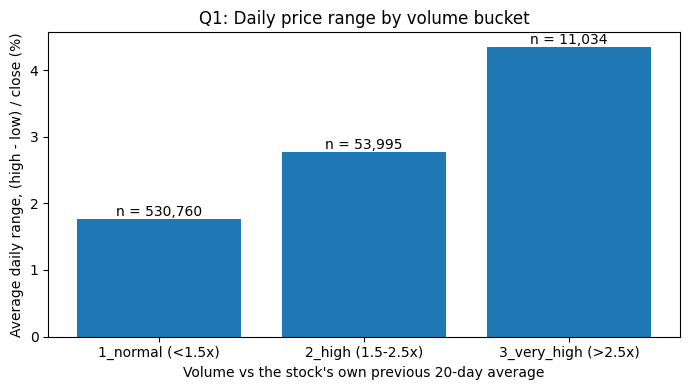

In [18]:
import os
import matplotlib.pyplot as plt
 
os.makedirs("task4/outputs", exist_ok=True)
 
# The result has only 3 rows, so it is safe to turn into pandas for plotting
q1_pdf = q1_result.toPandas()
q1_pdf.to_csv("task4/outputs/q1_volume_buckets.csv", index=False)
 
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(q1_pdf["bucket"], q1_pdf["avg_day_range"] * 100)
 
# Write the group size on top of each bar
for bar, n in zip(bars, q1_pdf["n_rows"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"n = {n:,}", ha="center", va="bottom")
 
ax.set_xlabel("Volume vs the stock's own previous 20-day average")
ax.set_ylabel("Average daily range, (high - low) / close (%)")
ax.set_title("Q1: Daily price range by volume bucket")
plt.tight_layout()
plt.savefig("task4/outputs/q1_chart.png", dpi=150)
plt.show()


In [19]:
# CHANGED (Task 5): Calista's try/except fallback to the laptop folder "task3_outputs" is removed,
# so the notebook always reads THIS run's predictions on HDFS (and fails loudly if they're missing).
PRED_PATH = f"{OUT_BASE.rstrip('/')}/reference_test_predictions"
print("reading predictions from", PRED_PATH)
 
spark.read.parquet(PRED_PATH).createOrReplaceTempView("predictions")
print("prediction rows (before removing duplicates):", spark.table("predictions").count())
 

reading predictions from hdfs:///project/runs/full_alt_partitions8_r3/task3/reference_test_predictions
prediction rows (before removing duplicates): 25441


In [20]:
# Q2 SQL is written here so the notebook does not need any extra file.
# A readable copy is in task4/hive/q2_model_errors.sql
q2_view_sql = """
CREATE OR REPLACE TEMPORARY VIEW q2_base AS
WITH pred AS (
  SELECT DISTINCT symbol, CAST(anchor_date AS STRING) AS anchor_date, prediction, label
  FROM predictions
)
SELECT p.symbol,
       substr(p.anchor_date, 1, 7)  AS month,
       p.prediction,
       p.label,
       w.vol_12w                    AS baseline,
       NTILE(3) OVER (ORDER BY w.vol_52w) AS grp
FROM pred p
JOIN project.weekly_all w
  ON p.symbol = w.ticker
 AND p.anchor_date = CAST(w.anchor_date AS STRING)
"""
 
q2_month_sql = """
SELECT month,
       COUNT(*)                              AS n,
       SQRT(AVG(POW(prediction - label, 2))) AS rmse_model,
       SQRT(AVG(POW(baseline   - label, 2))) AS rmse_base,
       AVG(ABS(prediction - label))          AS mae_model,
       AVG(ABS(baseline   - label))          AS mae_base
FROM q2_base
GROUP BY month
ORDER BY month
"""
 
q2_group_sql = """
SELECT CASE grp WHEN 1 THEN '1_calm' WHEN 2 THEN '2_medium' ELSE '3_volatile' END AS grp_name,
       COUNT(*)                              AS n,
       SQRT(AVG(POW(prediction - label, 2))) AS rmse_model,
       SQRT(AVG(POW(baseline   - label, 2))) AS rmse_base,
       AVG(ABS(prediction - label))          AS mae_model,
       AVG(ABS(baseline   - label))          AS mae_base
FROM q2_base
GROUP BY grp
ORDER BY grp
"""
 
spark.sql(q2_view_sql)                  # creates the q2_base view
q2_month = spark.sql(q2_month_sql)      # error by month
q2_group = spark.sql(q2_group_sql)      # error by calm / medium / volatile
 
q2_month.show()
q2_group.show()
print("rows in q2_base:", spark.table("q2_base").count())   # expect 25441 on the full profile
 

+-------+----+--------------------+--------------------+--------------------+--------------------+
|  month|   n|          rmse_model|           rmse_base|           mae_model|            mae_base|
+-------+----+--------------------+--------------------+--------------------+--------------------+
|2017-01|1992|0.010340295342038407|0.012089599821483946|0.006296271458457175|0.008118673067073458|
|2017-02|1992|0.008495170016210491|0.009583943976543165|0.005844564128095558|0.006747028206774...|
|2017-03|2495| 0.00720706764463333|0.008364161811442509|0.004991817707140392|0.005780375224368268|
|2017-04|1996|0.008596818622476085|0.009356658316206787|0.005718722932004168|0.006176753499477534|
|2017-05|1996|0.008312417807366215|0.008585849771680507|0.005715360019070058|0.005833247731535974|
|2017-06|2495|0.007369337736766...|0.007818030972611792|0.004883941542914584|0.005154615465215...|
|2017-07|1996|0.010317495351300904|0.010655350275201385|0.006272986293362482|0.006708053382625597|
|2017-08|1

26/11/10 10:15:32 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:32 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:32 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:32 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 1

+----------+----+--------------------+--------------------+--------------------+--------------------+
|  grp_name|   n|          rmse_model|           rmse_base|           mae_model|            mae_base|
+----------+----+--------------------+--------------------+--------------------+--------------------+
|    1_calm|8481|0.006088047039171901|0.006211693637488707|0.004119165135480732|0.004120912485846...|
|  2_medium|8480|0.008147574082073334|0.008607532914535415|0.005290875689332895|0.005823866159238232|
|3_volatile|8480|0.011542056287377676|0.013353424659057271|0.007482861610732405|0.009241797115928813|
+----------+----+--------------------+--------------------+--------------------+--------------------+

rows in q2_base: 25441


26/11/10 10:15:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 10:15:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/10 1

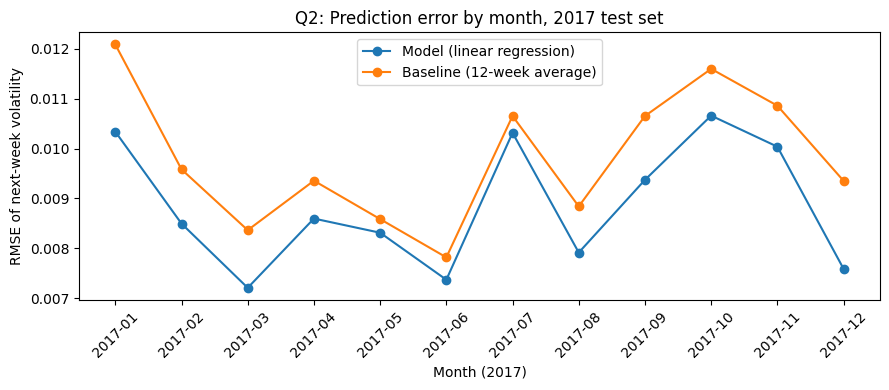

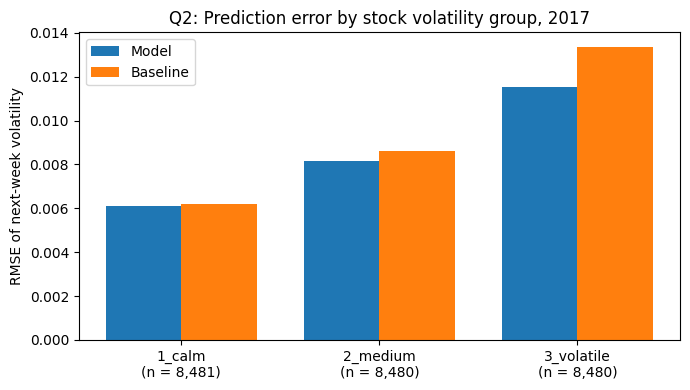

In [21]:
import os
import matplotlib.pyplot as plt
 
os.makedirs("task4/outputs", exist_ok=True)
 
# Both results are tiny (12 and 3 rows), so pandas is fine for plotting
by_month = q2_month.toPandas().set_index("month")
by_group = q2_group.toPandas().set_index("grp_name")
by_month.to_csv("task4/outputs/q2_error_by_month.csv")
by_group.to_csv("task4/outputs/q2_error_by_group.csv")
 
# Chart 1: error by month
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_month.index, by_month["rmse_model"], marker="o", label="Model (linear regression)")
ax.plot(by_month.index, by_month["rmse_base"], marker="o", label="Baseline (12-week average)")
ax.set_xlabel("Month (2017)")
ax.set_ylabel("RMSE of next-week volatility")
ax.set_title("Q2: Prediction error by month, 2017 test set")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("task4/outputs/q2_chart_by_month.png", dpi=150)
plt.show()
 
# Chart 2: error by volatility group
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(by_group))
w = 0.38
ax.bar([i - w / 2 for i in x], by_group["rmse_model"], w, label="Model")
ax.bar([i + w / 2 for i in x], by_group["rmse_base"], w, label="Baseline")
ax.set_xticks(list(x))
ax.set_xticklabels([f"{g}\n(n = {n:,})" for g, n in zip(by_group.index, by_group["n"])])
ax.set_ylabel("RMSE of next-week volatility")
ax.set_title("Q2: Prediction error by stock volatility group, 2017")
ax.legend()
plt.tight_layout()
plt.savefig("task4/outputs/q2_chart_by_group.png", dpi=150)
plt.show()
 
PIPE_T["task4_total"] = round(time.time() - T4, 1)      # CHANGED (Task 5): stop the Task 4 clock
 


In [22]:
PIPE_T["end_to_end"] = round(time.time() - T0, 1)
import urllib.request, datetime
 
def ui_get(base, path):
    return json.load(urllib.request.urlopen(f"{base}/api/v1/applications/{path}", timeout=30))
 
def stage_evidence(app_id, base):
    # Spark lecture, "Spark UI evidence": tasks, input, shuffle and spill per application
    try:
        try:
            stages = ui_get(base, f"{app_id}/stages")
        except Exception:
            stages = ui_get(base, f"{app_id}/1/stages")
        keys = ["numCompleteTasks", "inputBytes", "shuffleReadBytes", "shuffleWriteBytes",
                "memoryBytesSpilled", "diskBytesSpilled"]
        out = {k: sum(s.get(k, 0) for s in stages) for k in keys}
        out["stages"] = len(stages)
        return out
    except Exception as e:
        return f"unavailable: {e}"
 
nb_app = spark.sparkContext.applicationId
spark_ui = {nb_app: stage_evidence(nb_app, spark.sparkContext.uiWebUrl)}
for a in sorted(set(APP_IDS) - {nb_app}):          # Task 2's spark-submit app, via the History Server
    ev = stage_evidence(a, "http://localhost:18080")
    if isinstance(ev, dict):                          # Streaming and Hive/Tez apps aren't Spark: skipped
        spark_ui[a] = ev
try:
    mem = [{"id": e["id"], "maxMemory": e["maxMemory"],
            "peakJVMHeap": e.get("peakMemoryMetrics", {}).get("JVMHeapMemory")}
           for e in ui_get(spark.sparkContext.uiWebUrl, f"{nb_app}/executors")]
except Exception as e:
    mem = f"unavailable: {e}"
 
record = {
    "run_id": RUN_ID, "profile": PROFILE, "config": CONFIG_NAME, "repeat": REPEAT,
    "shuffle_partitions": SHUFFLE_PARTITIONS, "finished_utc": datetime.datetime.utcnow().isoformat() + "Z",
    "stage_seconds": PIPE_T, "yarn_app_ids": sorted(set(APP_IDS)),
    "raw_rows": spark.read.text(RAW_PATH).count() - 1,
    "accepted_rows": spark.table("project.prices_cleaned").count(),
    "rejected_rows": spark.table("project.prices_rejected").count(),
    "weekly_rows": TASK2_EXPECTED_ROWS,
    "final_model": best["model"] + " " + best["params"], "test_model": test_metrics, "test_baseline": base_test,
    "hdfs_du": {p: sh(f"hadoop fs -du -s {p}").split()[:2] for p in [RAW_PATH, "/project/prepared", RUN_DIR]},
    "hdfs_report": sh("hdfs dfsadmin -report | grep -E 'Name:|DFS Used:|DFS Remaining:'"),
    "spark_ui_evidence": spark_ui,
    "executor_memory": mem,
}
(EVID / "run_record.json").write_text(json.dumps(record, indent=2))
with open("task5_outputs/timings.jsonl", "a") as f:
    f.write(json.dumps(record) + "\n")
print(json.dumps(PIPE_T, indent=2)); print(json.dumps(spark_ui, indent=2))
spark.stop()


$ hadoop fs -du -s /project/raw/prices/all_stocks_5yr.csv
$ hadoop fs -du -s /project/prepared
$ hadoop fs -du -s /project/runs/full_alt_partitions8_r3
$ hdfs dfsadmin -report | grep -E 'Name:|DFS Used:|DFS Remaining:'
{
  "t2_streaming_audit": 32.1,
  "t2_hive_register": 12.4,
  "t2_spark_features": 141.2,
  "t2_hive_reconcile": 26.4,
  "spark_session_start": 13.5,
  "task3_total": 103.0,
  "task4_total": 11.3,
  "end_to_end": 348.3
}
{
  "application_1794303890982_0015": {
    "numCompleteTasks": 3628,
    "inputBytes": 4657608573,
    "shuffleReadBytes": 56391950,
    "shuffleWriteBytes": 55048459,
    "memoryBytesSpilled": 0,
    "diskBytesSpilled": 0,
    "stages": 970
  },
  "application_1794303890982_0013": {
    "numCompleteTasks": 23,
    "inputBytes": 159284910,
    "shuffleReadBytes": 23418568,
    "shuffleWriteBytes": 23418568,
    "memoryBytesSpilled": 0,
    "diskBytesSpilled": 0,
    "stages": 22
  }
}
